In [1]:
%load_ext autoreload 
%autoreload 2 

# Reference Distributions

Showing and comparing the distributions of outgoing and incoming references across two levels of granularity.

## 0. Set Up

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

from network_pluralism.setup.params import (
    DECISION_LEVEL_COLOR,
    PARAGRAPH_LEVEL_COLOR,
)
from network_pluralism.access.utils.df import get_incidence_edge_list


In [3]:
EXPORT_PATH = Path("../../figures_and_results/reference_distributions")
EXPORT_PATH.mkdir(parents=True, exist_ok=True)

In [4]:
def set_rcParams(**kwargs):
    params = {
        "pdf.fonttype": 42,
        "text.usetex": True,
        "font.family": "serif",
        "text.latex.preamble": r"\usepackage{amssymb}\usepackage{amsmath}\usepackage{amsfonts}",
        "font.size": 16,
        "legend.fontsize": 14,
        "legend.title_fontsize": 16,
        "axes.labelsize": 18,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "axes.spines.right": False,
        "axes.spines.top": False,
        "legend.columnspacing": 1.0,
        "legend.frameon": False,
        "lines.linewidth": 3,
    }
    for param in kwargs:
        if param in plt.rcParams.keys():
            params[param] = kwargs[param]
    for k, v in params.items():
        plt.rcParams[k] = v


set_rcParams()

## 1. Computations

In [5]:
incidence_edge_list_para = get_incidence_edge_list(d=3)
incidence_edge_list_dec = get_incidence_edge_list(d=2)

Out Matrix of shape (3111483, 93645)


Out Matrix of shape (74214, 93645)


In [6]:
dec_references_counts = incidence_edge_list_dec.groupby("r_sem_inc").sum()
para_references_counts = incidence_edge_list_para.groupby("r_sem_inc").sum()

dec_in_references_counts = incidence_edge_list_dec.groupby("c_sem_inc").count()
para_in_references_counts = incidence_edge_list_para.groupby("c_sem_inc").count()

/var/folders/8k/r3s46h0143vflzq6wy9_001r0000gp/T/ipykernel_69569/431042651.py:6: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim(0, 500)


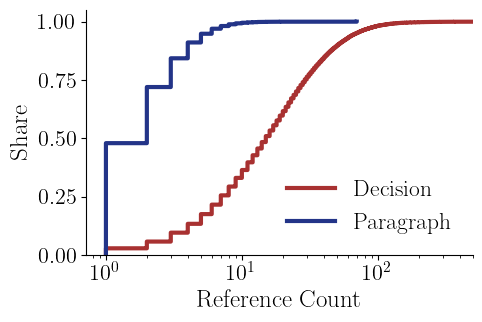

In [7]:
plt.figure(figsize=(5,3.5))
sns.ecdfplot(data=dec_references_counts, x="num", log_scale=[True, False], color=DECISION_LEVEL_COLOR, label="Decision")
sns.ecdfplot(
    data=para_references_counts, x="num", log_scale=[True, False], color=PARAGRAPH_LEVEL_COLOR, label="Paragraph"
)
plt.xlim(0, 500)
plt.ylim(0,1.05)

plt.xlabel("Reference Count")
plt.ylabel("Share")
plt.legend(fontsize=17)
plt.tight_layout()
plt.savefig(EXPORT_PATH / "ecdf_out_references.pdf",dpi=600)

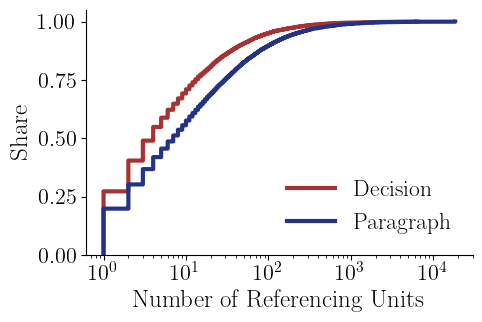

In [8]:
plt.figure(figsize=(5,3.5))

sns.ecdfplot(
    data=dec_in_references_counts, x="num", log_scale=[True, False], color=DECISION_LEVEL_COLOR, label="Decision"
)
sns.ecdfplot(
    data=para_in_references_counts, x="num", log_scale=[True, False], color=PARAGRAPH_LEVEL_COLOR, label="Paragraph"
)
plt.ylim(0,1.05)
plt.legend(fontsize=17)

plt.tight_layout()

plt.xlabel("Number of Referencing Units")
plt.ylabel('Share')
plt.savefig(EXPORT_PATH / "ecdf_in_references.pdf",dpi=600)